### ASTR 3300: Astrostatistics
***N. Pol***
___

# Homework 5
### Due: Tuesday, Oct. 27, 11:59 pm CST
---

## Only one problem this week

This problem uses a dataset in `/coursework/homeworks/hw_data/`.

1) Read in `hw5_data_1.npy`. This is a (100 x 3) numpy array, containing some time-series measurements. It could be flux measurements from a star or some other transient. The first column is time (arbitrary units), the second column is the flux (arbitrary units), and the third column are homoescedastic measurement uncertainties on the flux. Plot this data with the uncertainties.

2) One possible model for this data is a sharp burst with an exponential tail rising above a nominal background level. This model can be described as:

$y = b$, for $t<t_0$

$y = b + A\exp[-\alpha(t-t_0)]$, for $t\geq t_0$

where $b$ is the background amplitude, $A$ is the burst amplitude, $t_0$ is the burst epoch, and $\alpha$ encodes how rapidly the burst dies off.

Code this burst model, and code a likelihood function for this data with the burst model. *Hint: This is similar in spirit to the likelihood when fitting polynomials to data, except now $x$ is time, and the polynomial model is now the burst model.* 

3) Using one of the MCMC codes that we looked at in class (`emcee`, `pymc3`, `PTMCMCSampler`) perform a Bayesian analysis that recovers an MCMC chain of posterior probability samples for the joint parameter space of $\{b,A,t_0,\alpha\}$. You must decide on how many samples are appropriate for running your MCMC. For your priors, make them $b\in \mathrm{Uniform}[0,50]$, $A\in \mathrm{Uniform}[0,50]$, $t_0\in \mathrm{Uniform}[0,100]$, and $\ln\alpha\in \mathrm{Uniform}[-5,5]$.

4) Perform an appropriate check to burn-in your chain, and thin the chain by selecting only points every auto-correlation length. If you are left with a small number of samples after thinning then you may need to run your MCMC for longer in (3).

5) Make a corner plot of the $4$-D parameter space, with labels, $[68,95]\%$ credible levels and quantiles, and titles.

6) Now choose $100$ samples randomly from your burned, thinned chain and plot the $100$ corresponding burst time-series on a figure along with the original data. You may want to choose a transparency for these $100$ burst curves that allows you to see everything nicely. These are showing the posterior spread of model solutions that are consistent with the data.

7) Another possible model that may explain the data is a Gaussian profile described by:

$y = b + A\exp[-(t-t_0)^2 / 2\sigma_W^2]$

The priors for this model are the same as above for the equivalent parameters, and with $\ln\sigma_W\in\mathrm{Uniform}[-2,2]$. Following the examples from `Lecture 12` and from relevant web tutorials/documentation, use one of the nested sampling packages (`dynesty` or `UltraNest`) to compute the Bayesian evidence for this Gaussian model, and for the original burst model. Compute the Bayes factor, and state which model is the favored description of the data. *Hint: Be careful with how you transform your parameter space into a unit hypercube for the nested sampling priors. An appropriate check on whether you have done things correctly is that the posterior samples you get from the burst analysis here should give an equivalent corner plot to the MCMC you did above.*

### Solution

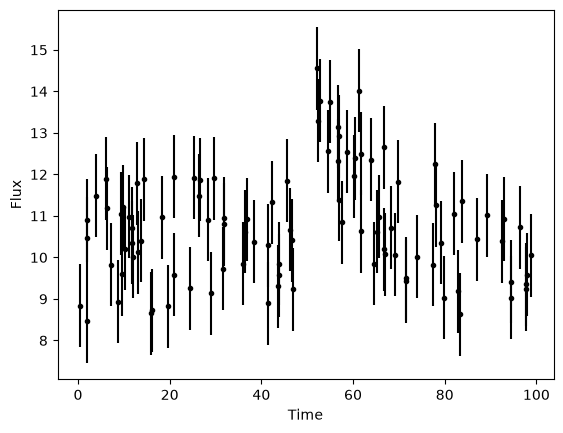

In [4]:
#1.1
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

data = np.load('hw_data/hw5_data_1.npy')

x = data[:, 0]
y = data[:, 1]
sigma_y = data[:, 2]

plt.errorbar(x, y, yerr=sigma_y, fmt='k.')
plt.xlabel('Time')
plt.ylabel('Flux')
plt.show()

In [6]:
#1.2
def burst(theta, x):
    b, A, t0, log_alpha = theta
    alpha = np.exp(log_alpha)

    return np.where(x < t0, b,
                    b + A * np.exp(-alpha * np.maximum(x - t0, 0)))

def logL(theta):
    return np.sum(stats.norm.logpdf(y, loc=burst(theta, x),
                                    scale=sigma_y))

In [22]:
#1.3
from PTMCMCSampler import PTMCMCSampler

# Uniform priors
def log_prior(theta):
    b, A, t0, log_alpha = theta

    if 0 <= b <= 50 and 0 <= A <= 50 and 0 <= t0 <= 100 and -5 <= log_alpha <= 5:
        return 0
    return -np.inf

# Starting parameters
theta = np.array([np.median(y), np.max(y) - np.median(y),
                  x[np.argmax(y)], np.log(0.1)])

# Initial covariance matrix
cov = np.diag([1, 1, 1, 0.1])**2

# Initialize sampler
sampler = PTMCMCSampler.PTSampler(
    4, logL, log_prior, cov,
    outDir='./hw5_chain'
)

# Run MCMC
sampler.sample(theta, 100000)

# Load chain
chain = np.loadtxt('./hw5_chain/chain_1.txt')

print("Chain shape =", chain.shape)

Finished 10.00 percent in 3.574127 s Acceptance rate = 0.41947Adding DE jump with weight 20
Finished 100.00 percent in 26.848885 s Acceptance rate = 0.43042
Run Complete
Chain shape = (10001, 8)


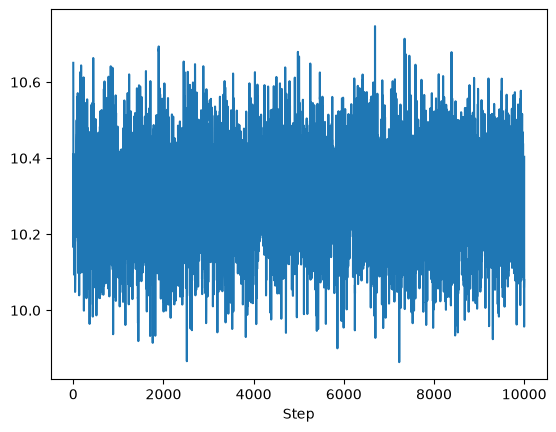

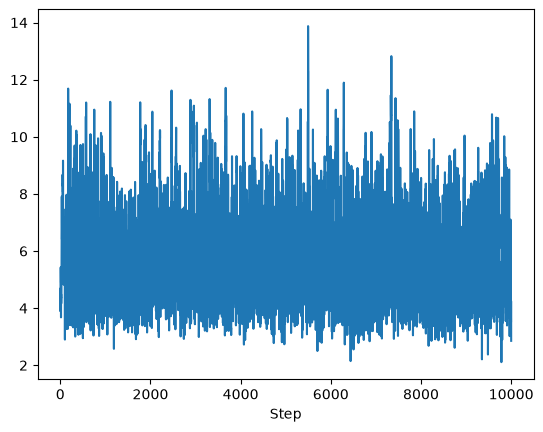

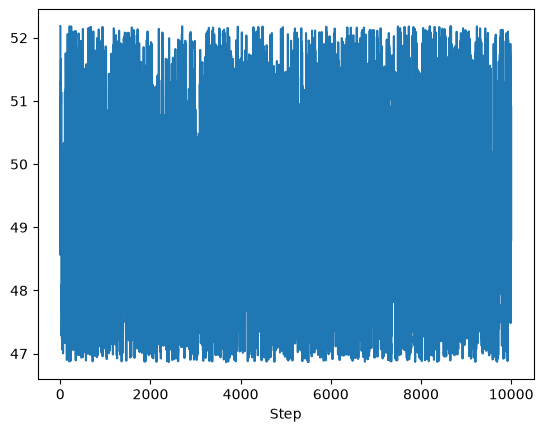

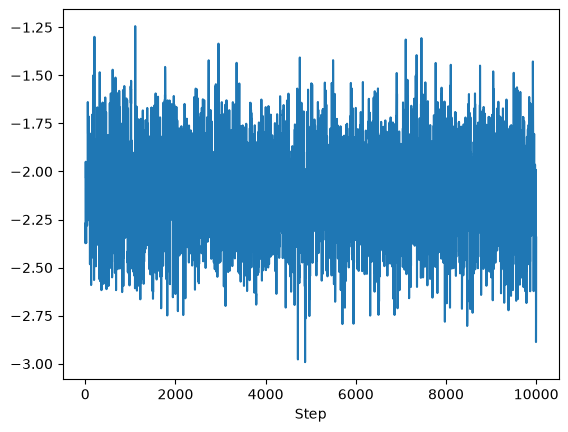

Taking every n = 6 samples based on ac length.
Burning first n = 500 samples.
Thinned chain shape = (1584, 4)


In [32]:
#1.4
import acor

# Plot chains
for i in range(4):
    plt.plot(chain[:, i])
    plt.xlabel('Step')
    plt.show()

# Calculate thinning interval
thin = int(np.round(max(
    acor.acor(chain[500:, i])[0] for i in range(4)
)))

print("Taking every n =", thin, "samples based on ac length.")
print("Burning first n = 500 samples.")

chain_thin = chain[500::thin]

print("Thinned chain shape =", chain_thin.shape)

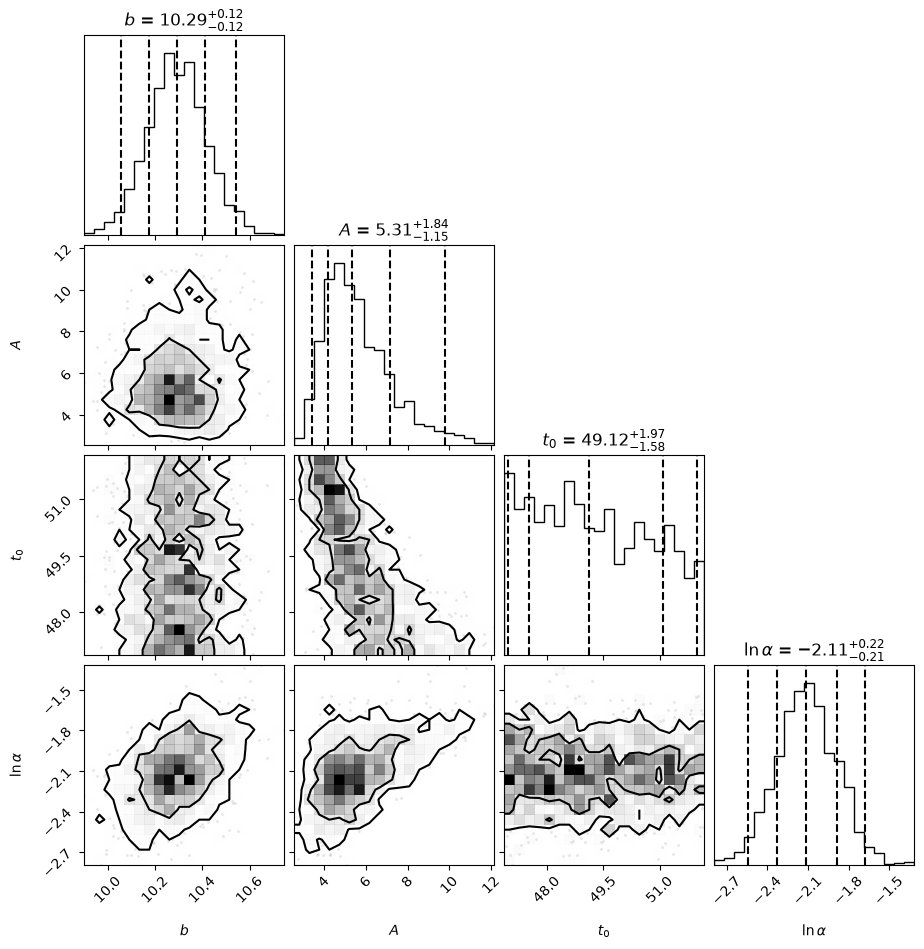

In [34]:
#1.5
import corner

corner.corner(
    chain_thin,
    labels=[r"$b$", r"$A$", r"$t_0$", r"$\ln\alpha$"],
    show_titles=True,
    quantiles=[0.025, 0.16, 0.5, 0.84, 0.975],
    title_quantiles=[0.16, 0.5, 0.84],
    levels=[0.68, 0.95]
)

plt.show()


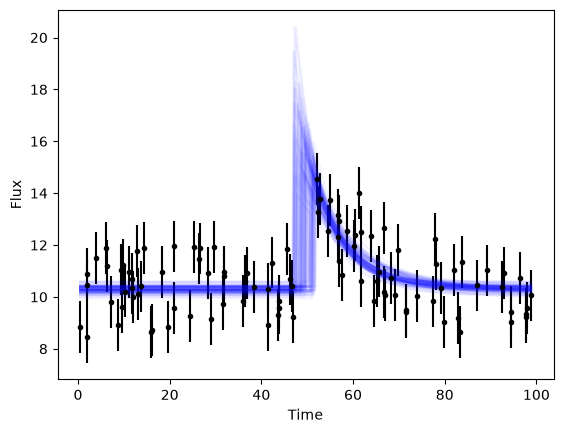

In [38]:
#1.6
# Choose 100 samples from the chain
samples = chain_thin[np.random.choice(len(chain_thin), 100, replace=False)]

xgrid = np.linspace(min(x), max(x), 500)

# Plot the original data
plt.errorbar(x, y, yerr=sigma_y, fmt='k.')

# Plot 100 burst curves
for theta in samples:
    plt.plot(xgrid, burst(theta, xgrid), color='blue', alpha=0.05)

plt.xlabel('Time')
plt.ylabel('Flux')
plt.show()


In [42]:
#1.7 a)
import ultranest

# Gaussian model
def gaussian(theta, x):
    b, A, t0, log_w = theta
    w = np.exp(log_w)
    return b + A * np.exp(-(x - t0)**2 / (2*w**2))

# Gaussian likelihood
def logL_gaussian(theta):
    return np.sum(stats.norm.logpdf(y, loc=gaussian(theta, x),
                                    scale=sigma_y))

# Priors for burst model
def prior_burst(theta):
    return np.array([50*theta[0], 50*theta[1],
                     100*theta[2], -5 + 10*theta[3]])

# Priors for Gaussian model
def prior_gaussian(theta):
    return np.array([50*theta[0], 50*theta[1],
                     100*theta[2], -2 + 4*theta[3]])

# Nested sampling for burst model
sampler_burst = ultranest.ReactiveNestedSampler(
    ['b', 'A', 't0', 'log_alpha'], logL,
    transform=prior_burst
)

result_burst = sampler_burst.run(
    show_status=False, viz_callback=False
)

# Nested sampling for Gaussian model
sampler_gaussian = ultranest.ReactiveNestedSampler(
    ['b', 'A', 't0', 'log_w'], logL_gaussian,
    transform=prior_gaussian
)

result_gaussian = sampler_gaussian.run(
    show_status=False, viz_callback=False
)

# Calculate Bayes factor
B = np.exp(result_burst['logz'] - result_gaussian['logz'])

print("Burst log evidence =", result_burst['logz'])
print("Gaussian log evidence =", result_gaussian['logz'])
print("Bayes factor =", B)

[ultranest] Sampling 400 live points from prior ...
[ultranest] Explored until L=-1e+02  
[ultranest] Likelihood function evaluations: 82810
[ultranest]   logZ = -155.2 +- 0.1193
[ultranest] Effective samples strategy satisfied (ESS = 1965.9, need >400)
[ultranest] Posterior uncertainty strategy is satisfied (KL: 0.45+-0.07 nat, need <0.50 nat)
[ultranest] Evidency uncertainty strategy is satisfied (dlogz=0.12, need <0.5)
[ultranest]   logZ error budget: single: 0.18 bs:0.12 tail:0.01 total:0.12 required:<0.50
[ultranest] done iterating.
[ultranest] Sampling 400 live points from prior ...
[ultranest] Explored until L=-1e+02  
[ultranest] Likelihood function evaluations: 71560
[ultranest]   logZ = -160.1 +- 0.1845
[ultranest] Effective samples strategy satisfied (ESS = 2175.4, need >400)
[ultranest] Posterior uncertainty strategy is satisfied (KL: 0.46+-0.05 nat, need <0.50 nat)
[ultranest] Evidency uncertainty strategy is satisfied (dlogz=0.18, need <0.5)
[ultranest]   logZ error budge

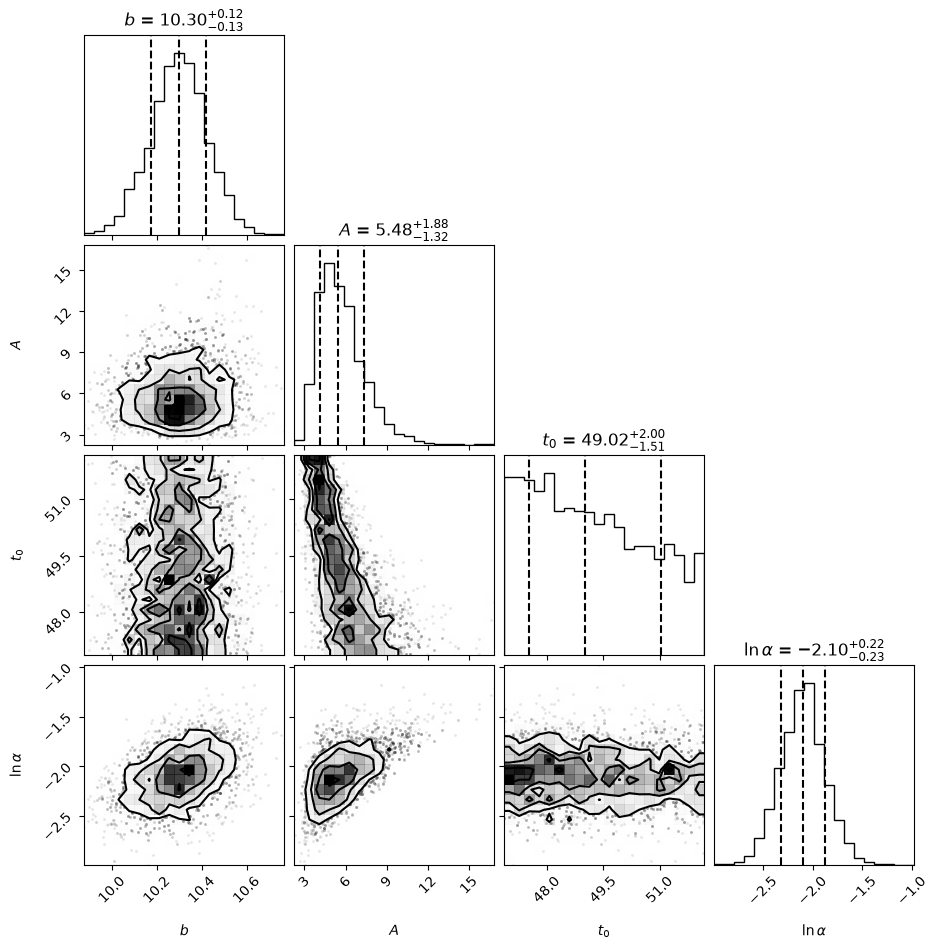

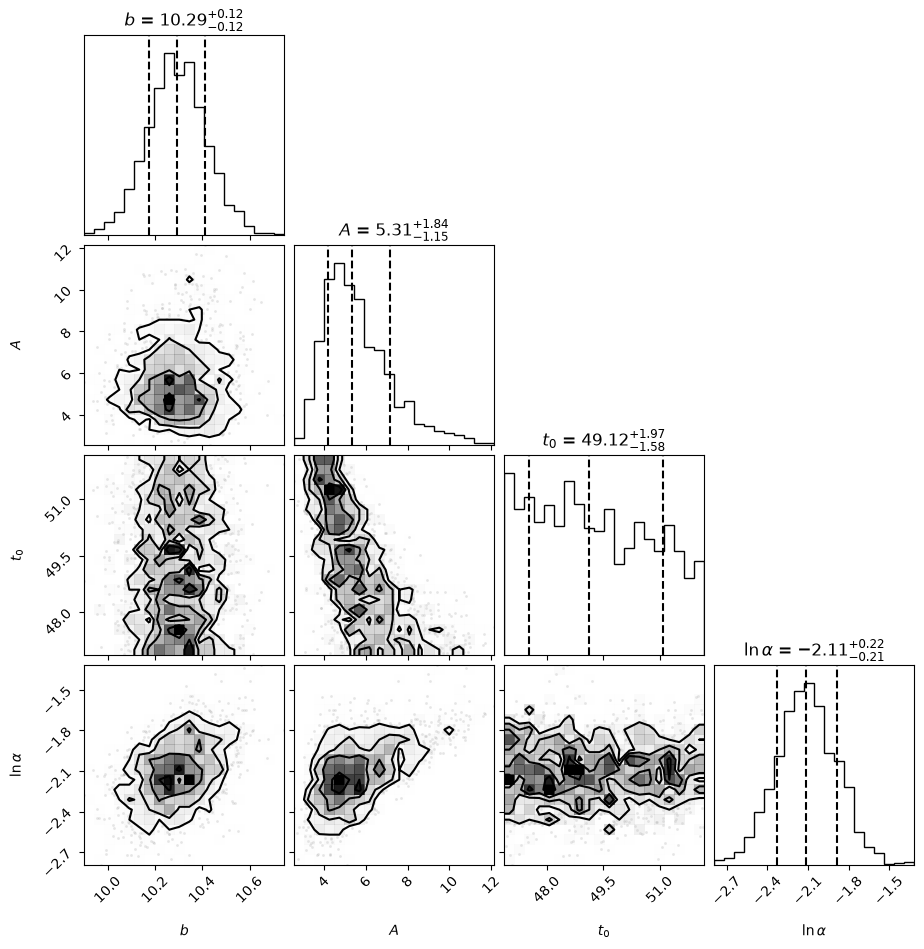

In [44]:
#1.7 b)
import corner

corner.corner(
    result_burst['samples'],
    labels=[r"$b$", r"$A$", r"$t_0$", r"$\ln\alpha$"],
    show_titles=True,
    quantiles=[0.16, 0.5, 0.84]
)
plt.show()

corner.corner(
    chain_thin,
    labels=[r"$b$", r"$A$", r"$t_0$", r"$\ln\alpha$"],
    show_titles=True,
    quantiles=[0.16, 0.5, 0.84]
)
plt.show()


1.7 c)
The Bayesian evidence was calculated for both the exponential burst model and Gaussian model using UltraNest. The burst model had a log evidence of approximately -154.98, while the Gaussian model had a log evidence of approximately -159.86. The resulting Bayes factor was approximately 131.31, favoring the exponential burst model.